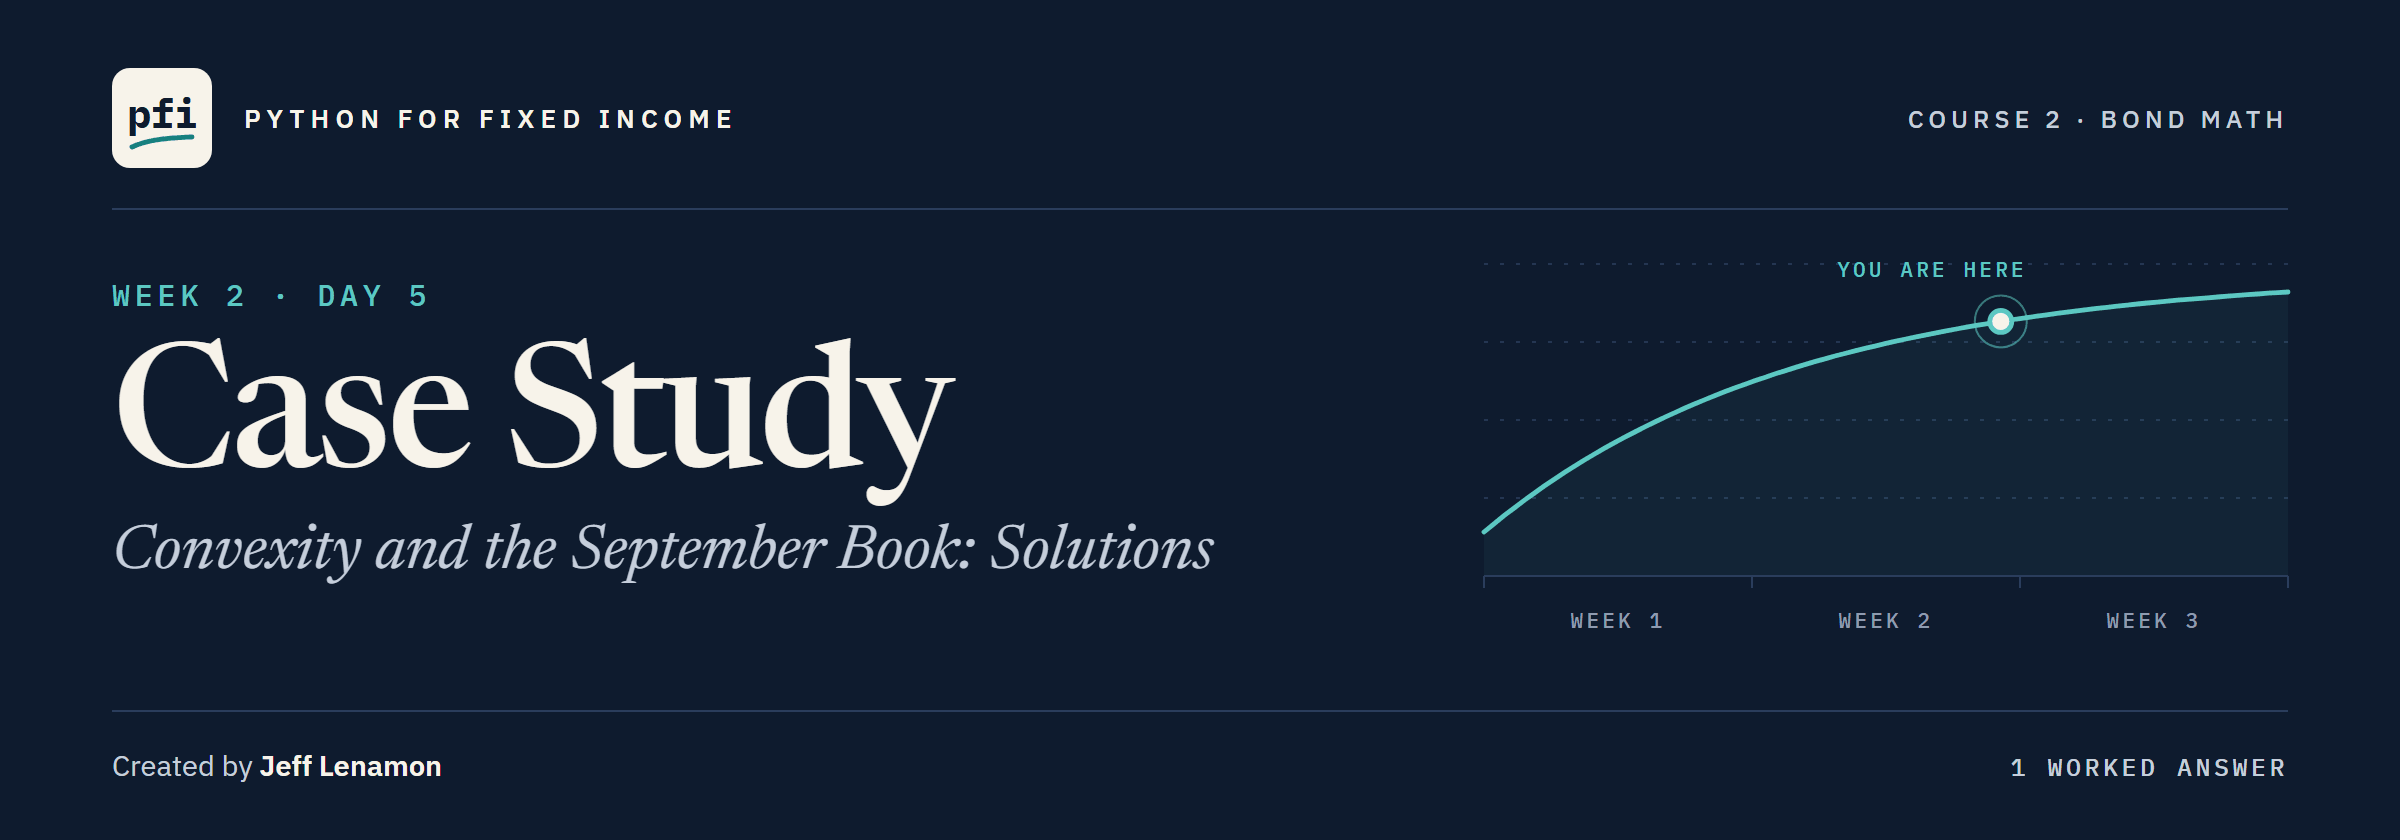

# Case Study: Convexity and the September Book: Solutions

Week 2, Day 5. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week2/day5/10_case_study_convexity_and_the_september_book_solutions.ipynb)

## Exercises

Run the next cells first: the work folder, with the module and tests as this notebook leaves them, the imports, `check`, and the bonds.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module and its tests as notebook 10 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(10, after=10)

Work folder pfi_course2_10_k4w7q2xr: 4 data files, the module as notebook 10 left it, 10 commits, tagged week1 and week2


In [2]:
import importlib
from datetime import date

import pandas as pd

import bondmath
settlement = date(2026, 11, 30)
reference = pd.read_csv('bondmath_excel_reference.csv')
print(len(reference), 'reference rows')

306 reference rows


In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [4]:
exercise_bonds = pd.DataFrame({
    'ticker': ['OSTV', 'TRNW', 'OSMC', 'CLDB'],
    'coupon_pct': [5.625, 4.375, 5.0, 8.25],
    'maturity': [date(2030, 9, 30), date(2028, 9, 30), date(2032, 9, 30), date(2034, 9, 30)],
    'yield_pct': [5.8, 4.3, 5.35, 8.6],
})
exercise_bonds

,ticker,coupon_pct,maturity,yield_pct
0,OSTV,5.625,2030-09-30,5.80
1,TRNW,4.375,2028-09-30,4.30
2,OSMC,5.000,2032-09-30,5.35
3,CLDB,8.250,2034-09-30,8.60


### Exercise 1

In [5]:
terms = list(zip(exercise_bonds['maturity'], exercise_bonds['coupon_pct'],
                 exercise_bonds['yield_pct']))
exercise_bonds['convexity'] = [bondmath.convexity(settlement, m, c, y) for m, c, y in terms]
ex1_calderby = exercise_bonds.set_index('ticker').loc['CLDB', 'convexity']
# idxmax: the row label of the largest convexity
ex1_largest = exercise_bonds.loc[exercise_bonds['convexity'].idxmax(), 'ticker']
exercise_bonds[['ticker', 'convexity']].round(4)

,ticker,convexity
0,OSTV,13.7541
1,TRNW,3.9181
2,OSMC,29.1746
3,CLDB,40.1518


In [6]:
check('Exercise 1 Calderby convexity', ex1_calderby, 40.151840380885986)
check('Exercise 1 largest convexity', ex1_largest, 'CLDB')

Exercise 1 Calderby convexity: correct
Exercise 1 largest convexity: correct


Calderby is the longest of the four, maturing in 2034, so it bends most.

### Exercise 2

In [7]:
osmere_maturity = date(2032, 9, 30)
osmere_modified = bondmath.modified_duration(settlement, osmere_maturity, 5.0, 5.35)
osmere_convexity = bondmath.convexity(settlement, osmere_maturity, 5.0, 5.35)
# +200 bp is dy = 0.02 as a decimal
ex2_estimate_pct = (-osmere_modified * 0.02 + 0.5 * osmere_convexity * 0.02 ** 2) * 100
dirty = bondmath.dirty_price(settlement, osmere_maturity, 5.0, 5.35)
ex2_full_pct = (bondmath.dirty_price(settlement, osmere_maturity, 5.0, 7.35) / dirty - 1) * 100
print(f'Estimate {ex2_estimate_pct:.6f}, full reprice {ex2_full_pct:.6f} percent')

Estimate -9.316371, full reprice -9.340811 percent


In [8]:
check('Exercise 2 estimate', ex2_estimate_pct, -9.316371448913852)
check('Exercise 2 full reprice', ex2_full_pct, -9.340810588211228)

Exercise 2 estimate: correct
Exercise 2 full reprice: correct


At 200 bp the two-term estimate is within 0.03 percent of the full reprice.

### Exercise 3

In [9]:
%%writefile -a bondmath.py


def convexity_adjustment(convexity: float, shift_bp: float) -> float:
    """The percent price change from convexity alone, for a yield move of shift_bp basis points.

    Units: convexity in years squared, unscaled, as bondmath.convexity returns it (not divided
    by 100 or by 2); shift_bp in basis points; the result in percent of the dirty price.
    Convention: 0.5 x convexity x dy ** 2 x 100, with dy = shift_bp / 10000, positive either way.
    Excel: =0.5*convexity_cell*(shift_bp/10000)^2*100
    """
    # the move as a decimal, then the second term of the estimate, in percent
    dy = shift_bp / 10000
    return 0.5 * convexity * dy ** 2 * 100

Appending to bondmath.py


In [10]:
%%writefile -a test_bondmath.py


def test_convexity_adjustment_hand_cases():
    # a convexity of 100 and 100 bp: 0.5 x 100 x 0.01 ** 2 x 100 = 0.5 percent
    assert bondmath.convexity_adjustment(100, 100) == pytest.approx(0.5, abs=1e-12)
    # the square makes a fall the same as a rise
    assert bondmath.convexity_adjustment(100, -100) == pytest.approx(0.5, abs=1e-12)
    # no move, no adjustment
    assert bondmath.convexity_adjustment(100, 0) == 0

Appending to test_bondmath.py


In [11]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.............................                                            [100%]
29 passed in 0.50s



In [12]:
# the file changed, so reload before calling the new function
importlib.reload(bondmath)
ex3_calderby = bondmath.convexity_adjustment(ex1_calderby, 100)
check('Exercise 3 Calderby adjustment', ex3_calderby, 0.20075920190442995)

Exercise 3 Calderby adjustment: correct


Half of 40.15 times 0.0001, in percent: 0.2008 percent of Calderby's price.

### Exercise 4: AI check

The bug: the assistant counts time in coupon periods, not years, so the result is in periods squared, four times too large at two coupons a year.
On an annual bond a period is a year, so a test on annual rows alone would have missed it.
The fix counts each time in years, as the docstring says.

In [13]:
# written for this course in the style of an AI assistant's answer, now fixed
def assistant_convexity(settlement, maturity, coupon_pct, yield_pct, frequency=2,
                        basis='30/360'):
    """Convexity in years squared, unscaled (not divided by 100 or by 2)."""
    dates = bondmath.coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = bondmath.coupon_period_days(settlement, maturity,
                                                                  frequency, basis)
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    total_pv, curvature = 0.0, 0.0
    for k in range(len(dates) - 1):
        cash_flow = coupon_pct / frequency + (100 if k == len(dates) - 2 else 0)
        # the fix: time to each cash flow in years
        time_years = (w + k) / frequency
        total_pv += cash_flow / (1 + period_yield) ** (w + k)
        curvature += (cash_flow * time_years * (time_years + 1 / frequency)
                      / (1 + period_yield) ** (frequency * time_years + 2))
    return curvature / total_pv

In [14]:
# the test file's reference rows and bond_inputs, read as today's test reads them
from test_bondmath import REFERENCE, bond_inputs
rows = [row for row in REFERENCE if row['coupnum'] != '1']
for row in rows:
    result = assistant_convexity(*bond_inputs(row))
    excel_value = float(row['convexity_fd'])
    message = f"{row['case_id']}: {result:.4f}, Excel {excel_value:.4f}"
    assert abs(result - excel_value) < 1e-3, message
print('Every row matches convexity_fd')

Every row matches convexity_fd


In [15]:
ex4_halvering = assistant_convexity(settlement, date(2036, 9, 30), 7.5, 7.7)
check('Exercise 4 Halvering convexity', ex4_halvering, 59.54736368900526)

Exercise 4 Halvering convexity: correct


[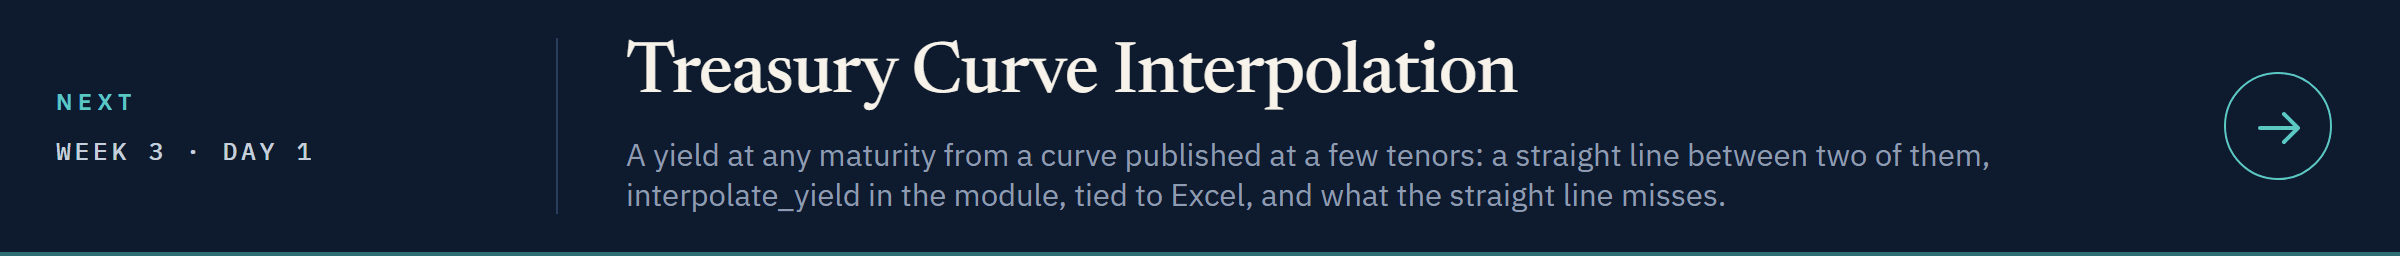](../../week3/day1/11_treasury_curve_interpolation.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week3/day1/11_treasury_curve_interpolation.ipynb)